# Mechanistic Interpretability for Physiological Signal Transformers
### Linear probes, causal interventions, confound detection, and attention probes on PPG

This notebook ports the [ARENA 1.3.1 Linear Probes](https://learn.arena.education/chapter1_transformer_interp/11_probing/) curriculum from language models to **transformers trained on physiological waveforms**. The mechanistic-interpretability machinery is identical. Only the substrate changes, from tokens of text to windows of photoplethysmography (PPG).

**The three papers the original chapter replicates, and their physiological analog here**

1. *Geometry of Truth* (Marks & Tegmark, COLM 2024). LLMs linearly encode truth. Here we ask whether a PPG transformer linearly encodes clinical state (tachycardia, vascular tone) that it was never explicitly supervised on.
2. *Detecting Strategic Deception* (Apollo Research, 2025). Probes trained on one distribution must generalize to another. Here the generalization question is **cross-site / cross-device**, the central obstacle in wearable physiology. A probe (or model) that leans on a device confound fails on a new site.
3. *Detecting High-Stakes Interactions* (McKenzie et al., NeurIPS 2025). Attention probes localize the diagnostic part of a sequence. Here we localize a transient critical event (a dropped/attenuated beat) inside a PPG window.

**What "probing" buys a physiological model.** If a *linear* probe recovers a clinical property from a hidden layer, that property is linearly represented in the model's state. That is the read side. The causal-intervention section is the write side, and it is where faithfulness lives. Classification accuracy alone never proves the model *uses* a direction. Patching it in and watching the output move does.

### Learning objectives
- Extract layer activations from a waveform transformer and visualize latent structure with PCA
- Train difference-of-means and logistic-regression probes, and compare direction, accuracy, and causal weight
- Patch a probe direction into the residual stream and shift the model's clinical readout, establishing causal implication
- Detect a **site/device confound** with a probe and reproduce the cross-site generalization failure that motivates site-invariant modeling
- Build an **attention probe** that pools over time with a single learned query, and read its weights to localize a critical event

A note on method choice. We train on **synthetic PPG with known generative factors** rather than a public dataset. This is deliberate and, for an interpretability tutorial, the stronger option. When you author the latent variables you have ground truth for what the model *could* represent, so a probe's success or failure is interpretable rather than confounded by unknown label noise. The generator is factored so you can swap in MIMIC-style or PPG-BP recordings at the marked seam once the pipeline is understood.


## 0. Setup

Pure CPU, no gated weights, no downloads. The whole notebook runs in a couple of minutes on a laptop.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, accuracy_score

torch.manual_seed(0)
np.random.seed(0)
device = "cpu"

FS   = 64     # sampling rate (Hz)
L    = 256    # window length (samples) -> 4 s window
P    = 16     # patch size (samples per token)
NTOK = L // P # tokens per window
DM   = 64     # model width

print(f"{L} samples per window, {NTOK} tokens, {DM}-dim residual stream")

256 samples per window, 16 tokens, 64-dim residual stream


## 0b. A PPG generator with known latent factors

Each window is built from factors we control, so we always know the ground truth.

- **heart rate** `hr` sets the fundamental frequency. This is the primary target the transformer will be trained to regress.
- **vascular tone** `tone` scales a second harmonic, a crude stand-in for the dicrotic notch. This is a *secondary* factor the model is never told about. We will probe for it.
- **respiratory band** `rr` amplitude-modulates the pulse.
- **site** injects a device signature (extra gain, slow baseline wander, a different noise floor). This is the **confound**, the analog of a spurious feature a probe might latch onto.
- **event** optionally attenuates one patch, a transient dropped/critical beat used later for the attention probe.

Every window is z-scored per channel, which is what a real pipeline does and which removes trivial gain cues.

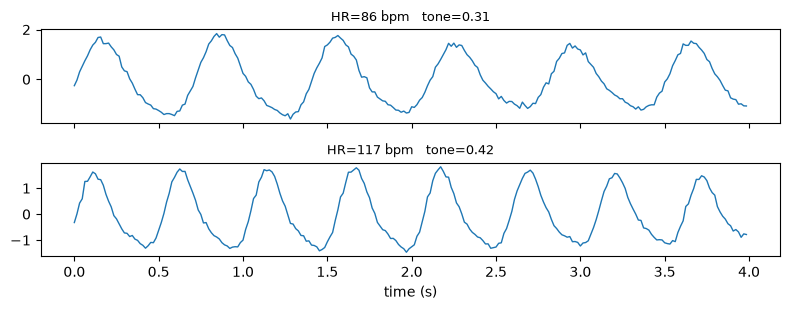

In [2]:
def generate_ppg(n, site=0, event_frac=0.0, hr_range=(50, 120), tone_range=(0.0, 1.0),
                 tone_coef=0.6, site_gain=1.25, seed=None):
    '''Return X (n, L) plus ground-truth factor arrays. This is the seam:
    replace the body with real recordings and keep the return signature to
    reuse the entire downstream notebook.'''
    rng = np.random.default_rng(seed)
    tt = np.arange(L) / FS
    X = np.zeros((n, L), np.float32)
    hr    = rng.uniform(*hr_range, n)
    tone  = rng.uniform(*tone_range, n)
    rr    = rng.uniform(0.15, 0.35, n)
    event = np.zeros(n, int)
    evloc = np.full(n, -1, int)
    for i in range(n):
        f = hr[i] / 60.0
        ph = 2 * np.pi * f * tt
        s = np.sin(ph) + tone_coef * tone[i] * np.sin(2 * ph - 0.9)   # systolic + dicrotic-ish
        s *= (1 + 0.15 * np.sin(2 * np.pi * rr[i] * tt))              # respiratory modulation
        if rng.random() < event_frac:                                 # transient critical event
            event[i] = 1
            loc = rng.integers(NTOK // 4, 3 * NTOK // 4)
            evloc[i] = loc
            a = loc * P
            s[a:a + P] *= 0.15                                        # attenuated beat
        if site == 1:                                                 # device signature (confound)
            s = site_gain * s + 0.4 * np.sin(2 * np.pi * 0.05 * tt + 1.0) + rng.normal(0, 0.08, L)
        else:
            s = s + rng.normal(0, 0.05, L)
        X[i] = s
    X = (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-6)
    return (X.astype(np.float32), hr.astype(np.float32), tone.astype(np.float32),
            np.full(n, site, np.int64), event, evloc)

# quick look at two windows
Xd, hrd, toned, *_ = generate_ppg(4, site=0, seed=1)
fig, ax = plt.subplots(2, 1, figsize=(8, 3.2), sharex=True)
for k in range(2):
    ax[k].plot(np.arange(L) / FS, Xd[k], lw=1)
    ax[k].set_title(f"HR={hrd[k]:.0f} bpm   tone={toned[k]:.2f}", fontsize=9)
ax[1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

## 1. Setup and visualizing representations

We train a small transformer encoder on the **primary task of heart-rate regression**, then set it aside and study its internals. Nothing below ever tells the model about tachycardia thresholds or vascular tone. Whatever structure a probe finds is therefore *emergent* from the HR objective, exactly the situation in the Geometry of Truth paper where truth structure emerges from language modeling.

The architecture patches the waveform into `NTOK` tokens, embeds each patch, runs three transformer layers, mean-pools, and reads out HR. We keep every layer's activations for probing.

In [3]:
class WaveEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Linear(P, DM)
        self.pos = nn.Parameter(torch.randn(1, NTOK, DM) * 0.02)
        layer = nn.TransformerEncoderLayer(DM, nhead=4, dim_feedforward=128,
                                           batch_first=True, dropout=0.0)
        self.tr = nn.TransformerEncoder(layer, num_layers=3)
        self.head = nn.Linear(DM, 1)

    def forward(self, x, patch=None, return_acts=False):
        # x: (B, L) -> tokens (B, NTOK, P)
        h = self.emb(x.view(x.shape[0], NTOK, P)) + self.pos
        acts = []
        for li, lyr in enumerate(self.tr.layers):
            h = lyr(h)
            if patch is not None and li == patch[0]:
                h = h + patch[1]           # additive intervention on the residual stream
            acts.append(h)                 # (B, NTOK, DM) per layer
        pooled = h.mean(1)
        y = self.head(pooled).squeeze(-1)
        if return_acts:
            return y, acts
        return y

Build a two-site dataset and train. Target is HR, z-scored for a stable loss.

In [4]:
Xa, hra, tonea, sa, *_ = generate_ppg(1500, site=0, seed=10)
Xb, hrb, toneb, sb, *_ = generate_ppg(1500, site=1, seed=11)
X    = np.concatenate([Xa, Xb])
hr   = np.concatenate([hra, hrb])
tone = np.concatenate([tonea, toneb])
site = np.concatenate([sa, sb])
pm = np.random.permutation(len(X))
X, hr, tone, site = X[pm], hr[pm], tone[pm], site[pm]

Xt = torch.tensor(X)
yt = torch.tensor((hr - 85) / 20.0)              # normalized HR target
ntr = 2400
train, test = slice(0, ntr), slice(ntr, len(X))

model = WaveEncoder()
opt = torch.optim.Adam(model.parameters(), 1e-3)
lossf = nn.MSELoss()
for ep in range(30):
    idx = torch.randperm(ntr)
    for b in range(0, ntr, 128):
        j = idx[b:b+128]
        opt.zero_grad()
        loss = lossf(model(Xt[j]), yt[j])
        loss.backward(); opt.step()

model.eval()
with torch.no_grad():
    pred = model(Xt[test]).numpy() * 20 + 85
print(f"Heart-rate MAE on held-out windows: {np.abs(pred - hr[test]).mean():.2f} bpm")

Heart-rate MAE on held-out windows: 0.74 bpm


### Extract activations and look for structure with PCA

We mean-pool the residual stream at a chosen layer to get one vector per window, then run PCA. If clinical state is linearly represented, it should separate along the top components **without any supervision from the probe**.

We define two binary properties the model was never trained on. Tachycardia (`hr > 100`) is tightly coupled to the HR objective, so it should be strongly represented. Vascular tone (`tone > 0.5`) is a genuinely independent factor.

In [4]:
def layer_features(layer):
    with torch.no_grad():
        _, acts = model(Xt, return_acts=True)
    return acts[layer].mean(1).numpy()      # (n, DM)

PROBE_LAYER = 1                              # early-to-mid, as in the original chapter
A = layer_features(PROBE_LAYER)
Atr, Ate = A[train], A[test]

y_tachy = (hr   > 100).astype(int)
y_tone  = (tone > 0.5).astype(int)

pcs = PCA(4).fit_transform(A)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for lbl, name in [(0, "normal"), (1, "tachycardia")]:
    mm = y_tachy == lbl
    ax[0].scatter(pcs[mm, 0], pcs[mm, 1], s=6, alpha=0.5, label=name)
ax[0].set_title("PCA colored by tachycardia (unsupervised)"); ax[0].legend(fontsize=8)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
for lbl, name in [(0, "low tone"), (1, "high tone")]:
    mm = y_tone == lbl
    ax[1].scatter(pcs[mm, 0], pcs[mm, 1], s=6, alpha=0.5, label=name)
ax[1].set_title("PCA colored by vascular tone (unsupervised)"); ax[1].legend(fontsize=8)
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.show()

NameError: name 'model' is not defined

### Layer sweep

Which layer best represents each property? Fit a quick logistic probe per layer and plot AUROC. In the original chapter truth peaks in early-to-mid layers. Watch where clinical state peaks here.

In [5]:
def probe_auroc(feats, y, tr, te):
    clf = LogisticRegression(max_iter=1000).fit(feats[tr], y[tr])
    return roc_auc_score(y[te], clf.decision_function(feats[te]))

layers = range(3)
au_tachy, au_tone = [], []
for Lyr in layers:
    F = layer_features(Lyr)
    au_tachy.append(probe_auroc(F, y_tachy, train, test))
    au_tone.append(probe_auroc(F, y_tone, train, test))

plt.figure(figsize=(6, 3.5))
plt.plot(list(layers), au_tachy, "o-", label="tachycardia")
plt.plot(list(layers), au_tone, "s-", label="vascular tone")
plt.ylim(0.5, 1.02); plt.xlabel("layer"); plt.ylabel("probe AUROC")
plt.title("Layer sweep: linear decodability by depth"); plt.legend(); plt.grid(alpha=0.3)
plt.xticks(list(layers)); plt.tight_layout(); plt.show()
print("tachycardia AUROC by layer:", [round(a,3) for a in au_tachy])
print("vascular tone AUROC by layer:", [round(a,3) for a in au_tone])

NameError: name 'model' is not defined

## 2. Training and comparing probes

Two classic probe estimators, following the chapter.

- **Difference of means (MM).** The direction is simply `mean(class 1) - mean(class 0)`. No fitting, no regularization, and as the chapter stresses, often the most *causally* faithful direction.
- **Logistic regression (LR).** Maximizes classification accuracy. It can exploit directions that separate the classes but that the model does not actually use downstream.

We compare their accuracy and the cosine between their directions. A high accuracy gap with a modest cosine is the tell that LR is fitting separability the model does not compute with.

In [7]:
# exercise: implement the two probe directions, then run the cell.
def mm_direction(feats, y, tr):
    mu1 = feats[tr][y[tr] == 1].mean(0)
    mu0 = feats[tr][y[tr] == 0].mean(0)
    return mu1 - mu0

def lr_direction(feats, y, tr):
    clf = LogisticRegression(max_iter=1000).fit(feats[tr], y[tr])
    return clf.coef_[0], clf

d_mm = mm_direction(A, y_tachy, train)
w_lr, clf_lr = lr_direction(A, y_tachy, train)

def acc_from_dir(direction, feats, y, tr, te):
    proj_tr = feats[tr] @ direction
    thr = 0.5 * (proj_tr[y[tr]==1].mean() + proj_tr[y[tr]==0].mean())
    proj_te = feats[te] @ direction
    return accuracy_score(y[te], (proj_te > thr).astype(int))

cos = float(d_mm @ w_lr / (np.linalg.norm(d_mm) * np.linalg.norm(w_lr)))
print(f"MM  probe accuracy : {acc_from_dir(d_mm, A, y_tachy, train, test):.3f}")
print(f"LR  probe accuracy : {accuracy_score(y_tachy[test], clf_lr.predict(Ate)):.3f}")
print(f"cosine(MM, LR)     : {cos:.3f}")

MM  probe accuracy : 0.925
LR  probe accuracy : 0.992
cosine(MM, LR)     : 0.826


The MM and LR directions are correlated but far from identical. They classify almost equally well, yet they point noticeably apart. Section 3 shows why that gap matters. Accuracy is not the quantity that certifies a direction is real.

### Probe an emergent factor

Repeat for vascular tone, which is independent of the HR objective. Strong AUROC here means the encoder built a representation of tone purely as a byproduct of learning to estimate rate.

In [8]:
clf_tone = LogisticRegression(max_iter=1000).fit(Atr, y_tone[train])
print(f"vascular-tone probe AUROC: {roc_auc_score(y_tone[test], clf_tone.decision_function(Ate)):.3f}")

vascular-tone probe AUROC: 0.988


## 3. Causal interventions

The crucial move. We take the MM tachycardia direction, **add it to the residual stream** at the probe layer, and read the HR head. If the direction is causally implicated, pushing along it should raise the predicted rate and pushing against it should lower it. This is activation patching, and it is the write-side test that classification accuracy cannot give you.

This is also the core of a *design-and-verify* stance on interpretability. A probe that reads a quantity is a hypothesis. A patch that moves the output along that direction is the verification.

baseline predicted HR : 84.7 bpm
patch  +MM direction  : 124.0 bpm   (delta +39.2)
patch  -MM direction  : 44.9 bpm   (delta -39.8)


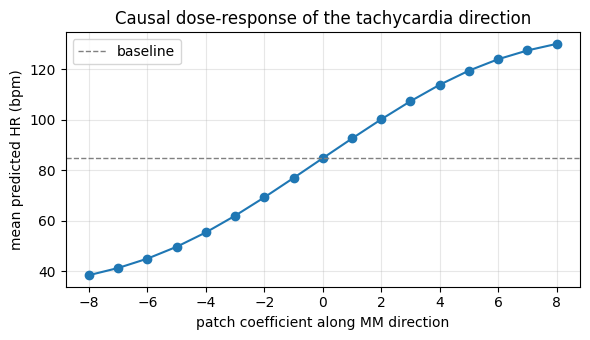

In [9]:
d = torch.tensor(d_mm / np.linalg.norm(d_mm), dtype=torch.float32)

with torch.no_grad():
    base = model(Xt[test]).numpy() * 20 + 85
    up   = model(Xt[test], patch=(PROBE_LAYER,  6.0 * d)).numpy() * 20 + 85
    down = model(Xt[test], patch=(PROBE_LAYER, -6.0 * d)).numpy() * 20 + 85

print(f"baseline predicted HR : {base.mean():.1f} bpm")
print(f"patch  +MM direction  : {up.mean():.1f} bpm   (delta {up.mean()-base.mean():+.1f})")
print(f"patch  -MM direction  : {down.mean():.1f} bpm   (delta {down.mean()-base.mean():+.1f})")

alphas = np.linspace(-8, 8, 17)
means = []
with torch.no_grad():
    for a in alphas:
        means.append((model(Xt[test], patch=(PROBE_LAYER, float(a) * d)).numpy() * 20 + 85).mean())
plt.figure(figsize=(6, 3.5))
plt.plot(alphas, means, "o-")
plt.axhline(base.mean(), ls="--", c="gray", lw=1, label="baseline")
plt.xlabel("patch coefficient along MM direction"); plt.ylabel("mean predicted HR (bpm)")
plt.title("Causal dose-response of the tachycardia direction"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### MM versus LR, causally

Now patch the LR direction with the same norm and coefficient and compare the swing. The chapter's headline result is that MM directions tend to be **more causally potent despite similar or lower classification accuracy**. Check whether that holds here.

In [10]:
dl = torch.tensor(w_lr / np.linalg.norm(w_lr), dtype=torch.float32)
with torch.no_grad():
    up_mm = model(Xt[test], patch=(PROBE_LAYER,  6.0 * d)).numpy()  * 20 + 85
    up_lr = model(Xt[test], patch=(PROBE_LAYER,  6.0 * dl)).numpy() * 20 + 85
print(f"HR swing from +6*MM direction: {up_mm.mean() - base.mean():+.1f} bpm")
print(f"HR swing from +6*LR direction: {up_lr.mean() - base.mean():+.1f} bpm")

HR swing from +6*MM direction: +39.2 bpm
HR swing from +6*LR direction: +44.9 bpm


## 4. Confounds and cross-site generalization

This is the physiological reframing of the deception-probe **generalization** question. In wearables the recurring failure is that a model or probe latches onto a **device/site signature** correlated with the label in the training distribution, then collapses on a new device. We show it three ways.

**4a. Positive control.** Our HR model learned a genuine, site-invariant feature (the pulse frequency), so a tachycardia probe trained on Site A transfers to Site B.

In [11]:
siteA = site == 0
trA = siteA.copy(); trA[ntr:] = False
teB = (site == 1).copy(); teB[:ntr] = False
clf_A = LogisticRegression(max_iter=1000).fit(A[trA], y_tachy[trA])
print(f"probe trained Site A -> Site A AUROC: {roc_auc_score(y_tachy[trA], clf_A.decision_function(A[trA])):.3f}")
print(f"probe trained Site A -> Site B AUROC: {roc_auc_score(y_tachy[teB], clf_A.decision_function(A[teB])):.3f}")

probe trained Site A -> Site A AUROC: 1.000
probe trained Site A -> Site B AUROC: 1.000


**4b. Is the confound even encoded?** Train a probe to predict *site* from the same activations. Low AUROC means the residual stream is device-invariant at this layer, which is what we want from a robust physiological model.

In [12]:
clf_site = LogisticRegression(max_iter=1000).fit(A[train], site[train])
print(f"site probe AUROC (clean HR model): {roc_auc_score(site[test], clf_site.decision_function(A[test])):.3f}")

site probe AUROC (clean HR model): 0.497


**4c. The failure mode.** Now we *induce* a shortcut. Train a fresh model on a subtle target (vascular-tone class) that is **perfectly confounded with site** in training. On a congruent test set the confound points the right way and accuracy looks fine. On an anti-correlated test set, where the device signature points at the wrong class, accuracy falls **below chance**. That collapse is the fingerprint of a model reading the confound instead of the physiology, and it is exactly what site-invariant training aims to prevent.

In [13]:
def make_split(n, site, tone_hi, seed):
    tr = (0.48, 0.56) if tone_hi else (0.44, 0.52)     # subtle, overlapping classes
    X_, _, _, _, _, _ = generate_ppg(n, site=site, hr_range=(55, 120),
                                     tone_range=tr, tone_coef=0.06, site_gain=1.4, seed=seed)
    return X_, np.full(n, int(tone_hi))

# training: high-tone always Site B, low-tone always Site A  (perfect confound)
XA, yA = make_split(1200, 0, False, 100)
XB, yB = make_split(1200, 1, True,  101)
Xtr_s = torch.tensor(np.concatenate([XA, XB])); ytr_s = torch.tensor(np.concatenate([yA, yB]).astype(np.float32))
# congruent test keeps the training correlation; anti test flips it
Xc = np.concatenate([make_split(400,0,False,102)[0], make_split(400,1,True, 103)[0]]); yc = np.r_[np.zeros(400), np.ones(400)]
Xn = np.concatenate([make_split(400,0,True, 104)[0], make_split(400,1,False,105)[0]]); yn = np.r_[np.ones(400),  np.zeros(400)]

shortcut = WaveEncoder(); op = torch.optim.Adam(shortcut.parameters(), 1e-3); bce = nn.BCEWithLogitsLoss()
for ep in range(40):
    idx = torch.randperm(len(Xtr_s))
    for b in range(0, len(Xtr_s), 128):
        j = idx[b:b+128]; op.zero_grad(); bce(shortcut(Xtr_s[j]), ytr_s[j]).backward(); op.step()
shortcut.eval()
with torch.no_grad():
    acc_tr = accuracy_score(ytr_s.numpy(), (shortcut(Xtr_s).numpy() > 0))
    acc_c  = accuracy_score(yc, (shortcut(torch.tensor(Xc)).numpy() > 0))
    acc_n  = accuracy_score(yn, (shortcut(torch.tensor(Xn)).numpy() > 0))
print(f"train accuracy            : {acc_tr:.2f}")
print(f"congruent-test accuracy   : {acc_c:.2f}   (confound aligned with label)")
print(f"anti-correlated test acc  : {acc_n:.2f}   (confound flipped -> collapse below chance)")

train accuracy            : 0.82
congruent-test accuracy   : 0.70   (confound aligned with label)
anti-correlated test acc  : 0.32   (confound flipped -> collapse below chance)


The read here is direct. A probe on the shortcut model's activations recovers *site* almost perfectly, and the model's decisions ride on it. This is why a cross-site transformer needs its site-invariance verified at the representation level, not just by held-out accuracy on the same devices. A probe is the cheapest such verifier.

## 5. Attention probes for high-stakes event detection

The last section ports the high-stakes-interaction attention probe. Instead of pooling with a fixed mean, we learn a **single query** that scores each token and takes a softmax-weighted sum before classifying. The distinctive payoff is **localization**. Its weights tell you *where* in the window the evidence sits, which fixed pooling cannot.

Our high-stakes target is a **transient critical event**, one attenuated beat dropped into half the windows at a known location. Be honest about the baselines. Because a dropped beat lowers the mean activation, a mean-pool probe detects *that* an event occurred about as well as the attention probe. A last-token probe does much worse, since the event rarely lands on the final token. The attention probe earns its place not on detection AUROC but on telling you which beat triggered the flag.

In [14]:
Xe, _, _, _, ev, evloc = generate_ppg(2000, site=0, event_frac=0.5, seed=200)
with torch.no_grad():
    _, ea = model(torch.tensor(Xe), return_acts=True)
H = ea[PROBE_LAYER].detach()             # (n, NTOK, DM) per-token activations
ntr2 = 1500

class AttentionProbe(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.q   = nn.Parameter(torch.randn(d) * 0.02)
        self.cls = nn.Linear(d, 1)
    def forward(self, Hs):
        score = (Hs @ self.q) / Hs.shape[-1] ** 0.5   # (B, NTOK)
        w = torch.softmax(score, dim=1)
        pooled = (w.unsqueeze(-1) * Hs).sum(1)
        return self.cls(pooled).squeeze(-1), w

ap = AttentionProbe(DM); opt2 = torch.optim.Adam(ap.parameters(), 5e-3); bce = nn.BCEWithLogitsLoss()
evt = torch.tensor(ev, dtype=torch.float32)
for ep in range(60):
    o, _ = ap(H[:ntr2]); opt2.zero_grad(); bce(o, evt[:ntr2]).backward(); opt2.step()

with torch.no_grad():
    o_te, w_te = ap(H[ntr2:])
auroc_attn = roc_auc_score(ev[ntr2:], o_te.numpy())

# baselines: last-token and mean-pool logistic probes on the same activations
last_tok = H[:, -1, :].numpy(); mean_tok = H.mean(1).numpy()
au_last = probe_auroc(last_tok, ev, slice(0, ntr2), slice(ntr2, len(ev)))
au_mean = probe_auroc(mean_tok, ev, slice(0, ntr2), slice(ntr2, len(ev)))
print(f"attention-probe AUROC : {auroc_attn:.3f}")
print(f"last-token  AUROC     : {au_last:.3f}")
print(f"mean-pool   AUROC     : {au_mean:.3f}")

attention-probe AUROC : 0.985
last-token  AUROC     : 0.699
mean-pool   AUROC     : 0.989


### Do the attention weights localize the event?

Detection AUROC is a wash against mean-pool. Localization is where the attention probe pays off. For every event window, check whether the peak attention token coincides with the injected event location.

peak attention within +/-1 token of the true event: 93% of event windows


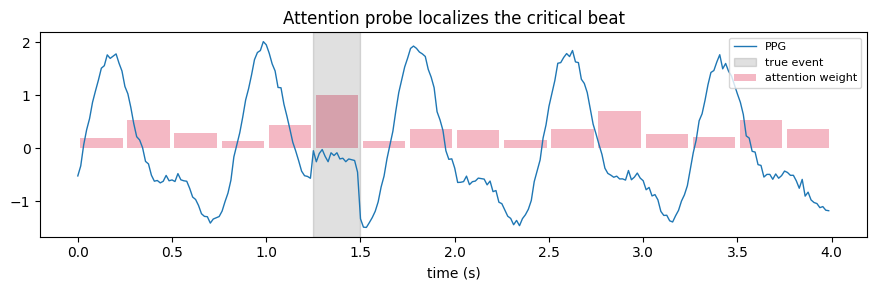

In [15]:
mask = ev[ntr2:] == 1
peak = w_te[mask].argmax(1).numpy()
truth = evloc[ntr2:][mask]
hit = (np.abs(peak - truth) <= 1).mean()
print(f"peak attention within +/-1 token of the true event: {hit*100:.0f}% of event windows")

# visualize one event window with its attention profile
ix = np.where(mask)[0][0]
gi = ntr2 + ix
plt.figure(figsize=(9, 3))
plt.plot(np.arange(L)/FS, Xe[gi], lw=1, label="PPG")
tcents = (np.arange(NTOK) * P + P/2) / FS
plt.bar(tcents, w_te[ix].numpy() * (np.abs(Xe[gi]).max()) * 3, width=P/FS*0.9,
        alpha=0.3, color="crimson", label="attention weight")
plt.axvspan(evloc[gi]*P/FS, (evloc[gi]+1)*P/FS, color="k", alpha=0.12, label="true event")
plt.xlabel("time (s)"); plt.title("Attention probe localizes the critical beat"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Closing: what probing does and does not certify

A compact map from this notebook back to a design-and-verify methodology for interpretable physiological models.

- **Linear decodability is necessary, not sufficient.** Sections 1 and 2 show clinical state is linearly present in the residual stream. That is a claim about *availability*, not *use*. A probe can succeed on a direction the model never reads.
- **Causal patching is the verification step.** Section 3 is the one that licenses a faithfulness claim. If patching a direction moves the clinical output monotonically, the model computes with it. Prefer difference-of-means directions when the causal question is what matters, since accuracy-optimized directions can overfit separability.
- **Confounds are the failure you must actively probe for.** Section 4 shows a model can pass held-out accuracy while riding a device signature. A site probe plus an anti-correlated test set catches it. This is the representational-level check a cross-site claim should include, over and above same-device accuracy.
- **Attention probes give cheap localization.** Section 5 recovers *where* the diagnostic evidence sits, which is the interpretability property clinicians actually ask for when a model flags an event.

### Swapping in real data
Replace the body of `generate_ppg` with a loader that returns `(X, hr, tone-or-label, site, event, evloc)` from MIMIC-style PPG, PPG-BP, or your own wearable recordings, keeping the return signature. Everything downstream (probes, patching, cross-site test, attention probe) runs unchanged. For real data, expect the layer sweep to matter more and the causal swings to be smaller and noisier.

### Original chapter and papers
- ARENA 1.3.1 Linear Probes, the source curriculum
- Marks & Tegmark, *The Geometry of Truth* (COLM 2024)
- Goldowsky-Dill et al., *Detecting Strategic Deception Using Linear Probes* (Apollo, 2025)
- McKenzie et al., *Detecting High-Stakes Interactions with Activation Probes* (NeurIPS 2025)
